In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout


In [4]:
url = "https://raw.githubusercontent.com/vihaankulkarni29/amr-dataset/main/Kaggle_AMR_Dataset_v1.0.csv"

df = pd.read_csv(url)

print("Dataset downloaded successfully!")
print(df.head())
print("Dataset shape:", df.shape)


Dataset downloaded successfully!
   Isolate_ID  Genome_Length_BP  GC_Content_Percent  gene_APH(3'')-Ib  \
0  AP035757.1           4784478               50.86                 0   
1  AP039418.1           5098687               50.58                 0   
2  AP040249.1           4940609               50.74                 0   
3  AP042483.1           5300047               50.74                 1   
4  AP042532.1           5451560               50.52                 0   

   gene_APH(3')-Ia  gene_APH(6)-Id  gene_CMY-59  gene_CRP  gene_CTX-M-14  \
0                0               0            0         1              0   
1                0               0            1         1              0   
2                0               0            0         1              1   
3                1               1            0         1              0   
4                0               0            0         1              0   

   gene_CTX-M-15  ...     biosample  bioproject  \
0              0  ..

In [5]:
df.columns = df.columns.str.strip()

gene_columns = [
    c for c in df.columns if c.startswith("gene_")
]

extra_columns = [
    c for c in ["Genome_Length_BP", "GC_Content_Percent"]
    if c in df.columns
]

feature_columns = gene_columns + extra_columns

target_columns = [
    c for c in df.columns if c.startswith("class_")
]

In [6]:
X = df[feature_columns].apply(
    pd.to_numeric, errors="coerce"
).fillna(0)

Y = df[target_columns].apply(
    pd.to_numeric, errors="coerce"
).fillna(0)

Y = (Y > 0).astype(int)

# Keep targets with two classes
valid_columns = [
    c for c in Y.columns if Y[c].nunique() == 2
]


In [7]:
Y = Y[valid_columns]

print("\nINPUT X:")
print(X.head())

print("\nOUTPUT Y:")
print(Y.head())

print("X Shape:", X.shape)
print("Y Shape:", Y.shape)

if X.shape[1] == 0 or Y.shape[1] == 0:
    raise ValueError("Required gene or resistance columns are missing.")



INPUT X:
   gene_APH(3'')-Ib  gene_APH(3')-Ia  gene_APH(6)-Id  gene_CMY-59  gene_CRP  \
0                 0                0               0            0         1   
1                 0                0               0            1         1   
2                 0                0               0            0         1   
3                 1                1               1            0         1   
4                 0                0               0            0         1   

   gene_CTX-M-14  gene_CTX-M-15  gene_CTX-M-27  gene_Escherichia_coli_acrA  \
0              0              0              0                           1   
1              0              0              0                           1   
2              1              0              0                           1   
3              0              0              0                           1   
4              0              0              0                           1   

   gene_Escherichia_coli_ampC  ...  gene_pmrF 

In [8]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.20,
    random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [10]:
model = Sequential()

model.add(Dense(
    64,
    activation="relu",
    input_shape=(X_train.shape[1],)
))

model.add(Dropout(0.2))

model.add(Dense(32, activation="relu"))

model.add(Dense(
    Y_train.shape[1],
    activation="sigmoid"
))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["binary_accuracy"]
)

model.summary()

history = model.fit(
    X_train,
    Y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    verbose=1
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,533 (25.52 KB)

 Trainable params: 6,533 (25.52 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - binary_accuracy: 0.4625 - loss: 0.7288 - val_binary_accuracy: 0.4750 - val_loss: 0.6968
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - binary_accuracy: 0.5938 - loss: 0.6579 - val_binary_accuracy: 0.6750 - val_loss: 0.6511
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - binary_accuracy: 0.7000 - loss: 0.6035 - val_binary_accuracy: 0.8500 - val_loss: 0.6120
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - binary_accuracy: 0.8500 - loss: 0.5690 - val_binary_accuracy: 0.8750 - val_loss: 0.5742
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - binary_accuracy: 0.9062 - loss: 0.5233 - val_binary_accuracy: 0.8750 - val_loss: 0.5363
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - binary_accuracy: 0.9375 - loss: 0.4755 - val_binary_accuracy: 0.8750 - val_loss: 0.4986
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - binary_accuracy: 0.9500 - loss: 0.4505 - val_binary_accuracy: 0.9500 - val_loss: 0.4595
Epoch 8/100
4/4 ━━━━

In [12]:
predictions = model.predict(X_test)

predicted_classes = (
    predictions >= 0.5
).astype(int)

print("\nCLASSIFICATION REPORT")

for i, name in enumerate(Y.columns):
    print("\nResistance Class:", name)

    print(classification_report(
        Y_test.iloc[:, i],
        predicted_classes[:, i],
        zero_division=0
    ))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step

CLASSIFICATION REPORT

Resistance Class: class_benzalkonium_chloride
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.90      1.00      0.95         9

    accuracy                           0.90        10
   macro avg       0.45      0.50      0.47        10
weighted avg       0.81      0.90      0.85        10


Resistance Class: class_diaminopyrimidine
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10


Resistance Class: class_lincosamide
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        10

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00     

In [13]:
accuracy = accuracy_score(
    Y_test.values.flatten(),
    predicted_classes.flatten()
)

print("Overall Label Accuracy:", accuracy * 100, "%")

all_predictions = model.predict(
    scaler.transform(X)
)

resistance = all_predictions.mean(axis=0)

drug_results = pd.DataFrame({
    "Antibiotic_Class": Y.columns,
    "Resistance_Probability": resistance,
    "Susceptibility_Score": 1 - resistance
})

drug_results = drug_results.sort_values(
    by="Susceptibility_Score",
    ascending=False
)

print("\nDRUG DISCOVERY RESULTS")
print(drug_results)

Overall Label Accuracy: 96.0 %
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step

DRUG DISCOVERY RESULTS
              Antibiotic_Class  Resistance_Probability  Susceptibility_Score
1      class_diaminopyrimidine                0.026810              0.973190
4            class_sulfonamide                0.231728              0.768272
2            class_lincosamide                0.978136              0.021864
0  class_benzalkonium_chloride                0.998125              0.001875
3              class_rhodamine                0.999239              0.000761


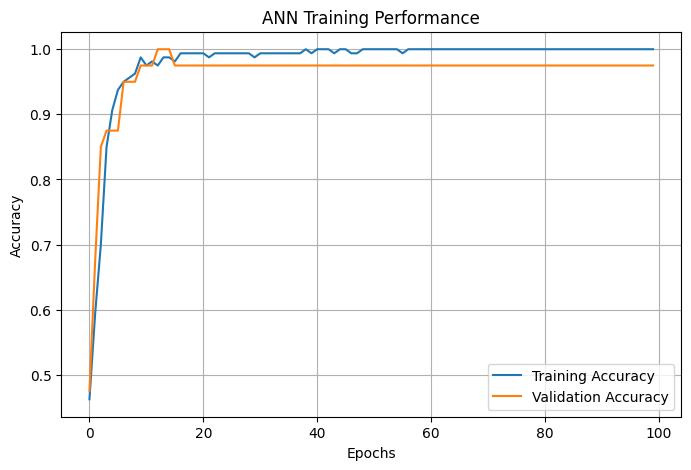

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["binary_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_binary_accuracy"],
    label="Validation Accuracy"
)

plt.title("ANN Training Performance")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


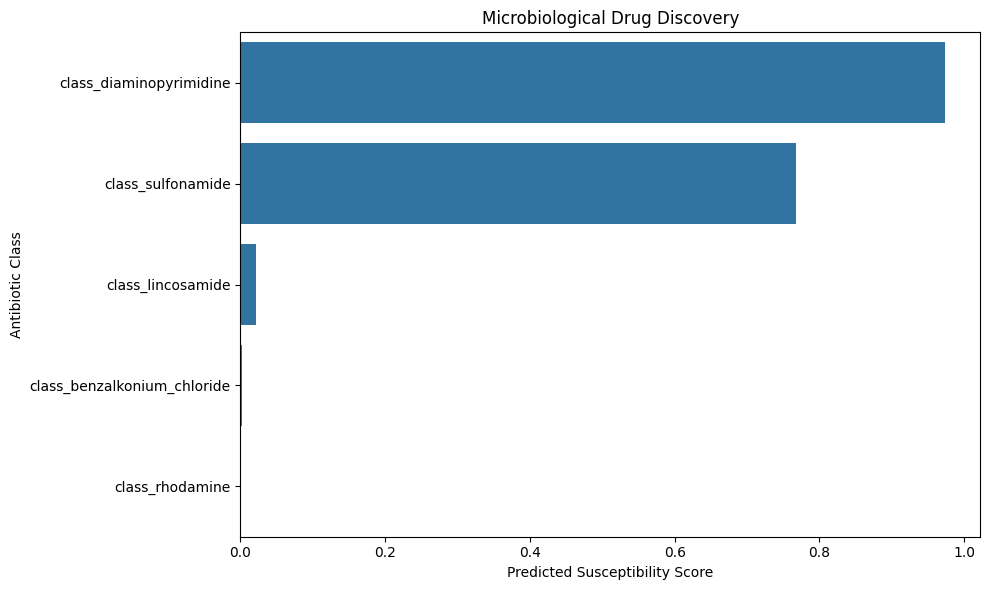

In [15]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=drug_results,
    x="Susceptibility_Score",
    y="Antibiotic_Class"
)

plt.title("Microbiological Drug Discovery")
plt.xlabel("Predicted Susceptibility Score")
plt.ylabel("Antibiotic Class")

plt.tight_layout()
plt.show()

In [16]:
drug_results.to_csv(
    "Microbiological_Drug_Discovery.csv",
    index=False
)

model.save("Microbiological_ANN_Model.keras")

print("\n================================")
print("PROJECT COMPLETED SUCCESSFULLY")
print("Dataset Loaded")
print("X and Y Defined")
print("Neural Network Trained")
print("Drug Resistance Predicted")
print("Graphs Generated")
print("CSV File Saved")
print("================================")



PROJECT COMPLETED SUCCESSFULLY
Dataset Loaded
X and Y Defined
Neural Network Trained
Drug Resistance Predicted
Graphs Generated
CSV File Saved
